<a href="https://colab.research.google.com/github/ArifahZhafirah/PEMBELAJARAN-MESIN/blob/main/JS10/Tugas-LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TUGAS LAB JS10 - Klasifikasi MNIST dengan ANN (TensorFlow)



# 1. Import library

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# 2. Load dataset MNIST

In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Data latih :", X_train.shape)   # (60000, 28, 28)
print("Data uji   :", X_test.shape)    # (10000, 28, 28)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Data latih : (60000, 28, 28)
Data uji   : (10000, 28, 28)


# 3. Pra pengolahan data
# a. Normalisasi piksel 0-255 -> 0-1

In [3]:
X_train = X_train.astype('float32') / 255.0
X_test  = X_test.astype('float32') / 255.0

# b. Flatten gambar 28x28 menjadi vektor 784 fitur (input ANN)

In [4]:
X_train = X_train.reshape(-1, 28*28)
X_test  = X_test.reshape(-1, 28*28)

# c. Split data latih menjadi data latih & validasi (80:20)

In [5]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)

y_train = np.array(y_train)
y_val   = np.array(y_val)
y_test  = np.array(y_test)

# 4. Membangun model ANN

In [6]:
model = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64,  activation='relu'),
    layers.Dense(10,  activation='softmax')   # 10 kelas: angka 0-9
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

# 5. Melatih model

In [7]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.9218 - loss: 0.2683 - val_accuracy: 0.9564 - val_loss: 0.1455
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9663 - loss: 0.1116 - val_accuracy: 0.9673 - val_loss: 0.1082
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9745 - loss: 0.0790 - val_accuracy: 0.9721 - val_loss: 0.0930
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9818 - loss: 0.0581 - val_accuracy: 0.9739 - val_loss: 0.0916
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9859 - loss: 0.0437 - val_accuracy: 0.9747 - val_loss: 0.0921
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9884 - loss: 0.0368 - val_accuracy: 0.9744 - val_loss: 0.0934
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9898 - loss: 0.0310 - val_accuracy: 0.9772 - val_loss: 0.0850
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9927 - loss: 0.0232

# 6. Evaluasi model pada data uji

In [8]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print("Akurasi Test:", test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9792 - loss: 0.1259
Akurasi Test: 0.979200005531311


# 7. Prediksi & metrik evaluasi (accuracy, precision, recall, confusion matrix)

In [9]:
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

print("Akurasi (accuracy_score):", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))       # precision, recall, f1-score per kelas

cm = confusion_matrix(y_test, y_pred)
print(cm)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Akurasi (accuracy_score): 0.9792
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.97      0.98      1032
           3       0.99      0.96      0.98      1010
           4       0.96      0.98      0.97       982
           5       0.98      0.98      0.98       892
           6       0.97      0.99      0.98       958
           7       0.97      0.98      0.98      1028
           8       0.97      0.98      0.97       974
           9       0.98      0.96      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000

[[ 971    0    1    0    1    0    5    1    1    0]
 [   0 1129    3    0    0    0    1    1    1    0]
 [   9    0 1006    0    3    0    3    6    5    0]
 [   0  

# Visualisasi confusion matrix

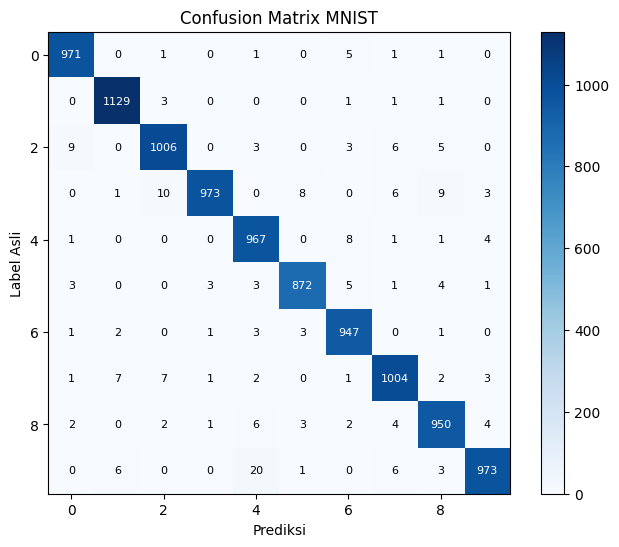

In [10]:
plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.title('Confusion Matrix MNIST')
plt.xlabel('Prediksi')
plt.ylabel('Label Asli')
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=8,
                 color='white' if cm[i, j] > cm.max()/2 else 'black')
plt.show()

# 8. Plot kurva akurasi & loss (deteksi overfitting/underfitting)

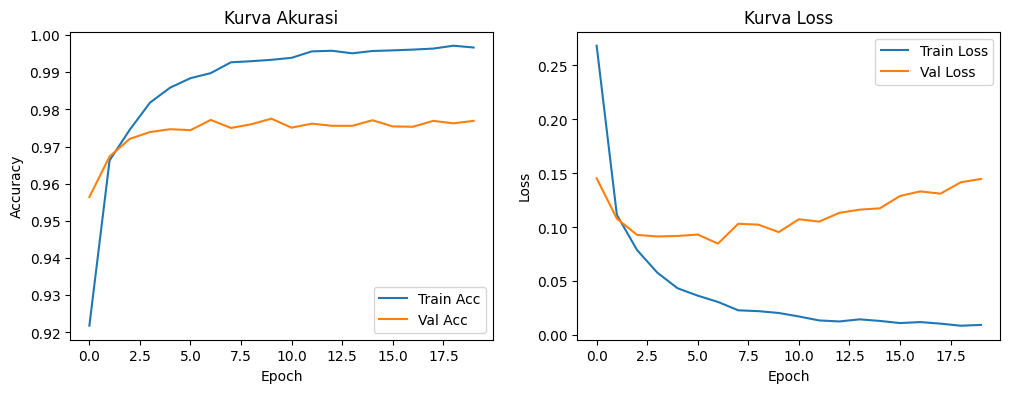

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'],     label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.title('Kurva Akurasi')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'],     label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.title('Kurva Loss')

plt.show()

# 9. Simpan model

In [12]:
model.save('mnist_ann_model.h5')
print("Model tersimpan sebagai mnist_ann_model.h5")

Model tersimpan sebagai mnist_ann_model.h5


# EKSPLORASI TUGAS LAB

# Fungsi bantu agar eksperimen konsisten

In [14]:
def build_model(hidden=(128, 64), activation='relu', input_dim=784):
    model = models.Sequential([layers.Input(shape=(input_dim,))])
    for units in hidden:
        model.add(layers.Dense(units, activation=activation))
    model.add(layers.Dense(10, activation='softmax'))
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# (a) EKSPLORASI METODE PRA PENGOLAHAN: /255 vs StandardScaler

In [17]:
print("--- Eksplorasi Pra Pengolahan ---")
from sklearn.preprocessing import StandardScaler

(Xa, ya), (Xb, yb) = tf.keras.datasets.mnist.load_data()
Xa = Xa.reshape(-1, 784).astype('float64')
Xb = Xb.reshape(-1, 784).astype('float64')

sc = StandardScaler()
Xa = sc.fit_transform(Xa)
Xb = sc.transform(Xb)

m = build_model()
m.fit(Xa, ya, epochs=5, batch_size=32, verbose=0)
_, acc = m.evaluate(Xb, yb, verbose=0)
print(f"StandardScaler -> Akurasi: {acc:.4f}")

--- Eksplorasi Pra Pengolahan ---
StandardScaler -> Akurasi: 0.9704


# (b) EKSPLORASI PEMILIHAN FITUR: PCA (784 fitur -> 100 fitur)

In [18]:
print("--- Eksplorasi Pemilihan Fitur (PCA) ---")
from sklearn.decomposition import PCA

(Xa, ya), (Xb, yb) = tf.keras.datasets.mnist.load_data()
Xa = Xa.reshape(-1, 784).astype('float32') / 255.0
Xb = Xb.reshape(-1, 784).astype('float32') / 255.0

pca = PCA(n_components=100)
Xa_pca = pca.fit_transform(Xa)
Xb_pca = pca.transform(Xb)

m = build_model(input_dim=100)
m.fit(Xa_pca, ya, epochs=5, batch_size=32, verbose=0)
_, acc = m.evaluate(Xb_pca, yb, verbose=0)
print(f"PCA 100 fitur  -> Akurasi: {acc:.4f}")


--- Eksplorasi Pemilihan Fitur (PCA) ---
PCA 100 fitur  -> Akurasi: 0.9762


# (c) EKSPLORASI ARSITEKTUR ANN (jumlah layer & neuron)

In [16]:
print("--- Eksplorasi Arsitektur ---")
arsitektur = [(32,), (64,), (128,), (128, 64), (256, 128, 64)]
for h in arsitektur:
    m = build_model(hidden=h)
    m.fit(X_train, y_train, epochs=5, batch_size=32, verbose=0)
    _, acc = m.evaluate(X_test, y_test, verbose=0)
    print(f"Arsitektur {str(h):16s} -> Akurasi: {acc:.4f}")

--- Eksplorasi Arsitektur ---
Arsitektur (32,)            -> Akurasi: 0.9584
Arsitektur (64,)            -> Akurasi: 0.9681
Arsitektur (128,)           -> Akurasi: 0.9726
Arsitektur (128, 64)        -> Akurasi: 0.9741
Arsitektur (256, 128, 64)   -> Akurasi: 0.9785


# (d) EKSPLORASI FUNGSI AKTIVASI

In [15]:
print("--- Eksplorasi Fungsi Aktivasi ---")
for act in ['relu', 'tanh', 'sigmoid']:
    m = build_model(activation=act)
    m.fit(X_train, y_train, epochs=5, batch_size=32, verbose=0)
    _, acc = m.evaluate(X_test, y_test, verbose=0)
    print(f"Aktivasi {act:8s} -> Akurasi: {acc:.4f}")

--- Eksplorasi Fungsi Aktivasi ---
Aktivasi relu     -> Akurasi: 0.9753
Aktivasi tanh     -> Akurasi: 0.9704
Aktivasi sigmoid  -> Akurasi: 0.9711
